# Speech Denoising on Noisy AudioMNIST with a U-Net

This notebook removes additive noise from short spoken-digit recordings by working on
**log-mel spectrograms**. A network receives the spectrogram of a noisy recording and predicts the
spectrogram of the clean recording. Audio can then be reconstructed from the output with Griffin-Lim.

**Pipeline:** exploratory data analysis → pairing of noisy and clean recordings → fixed-size
(128 × 128) z-normalised log-mel spectrograms → a baseline convolutional autoencoder → a U-Net with an
ImageNet-pretrained ResNet-34 encoder → evaluation with MSE and SNR, per-speaker and per-digit analysis,
and waveform reconstruction.

**Author:** Kiana Hashemi

## Configuration

Paths and run settings come from environment variables, so the notebook runs unchanged locally, in
Docker or in CI:

| Variable | Default | Meaning |
|---|---|---|
| `AUDIO_DATA_DIR` | `../data/noisy-audio-mnist` | folder containing `audioMNIST_meta.txt` and the speaker folders |
| `QUICK_RUN` | `0` | `1` = smoke test: train 1 epoch per model with batch size 8 (use with a downloaded sample) |
| `NUM_WORKERS` | `2` | DataLoader worker processes |

> **About the saved outputs:** the outputs stored in this notebook come from the complete run on the full
> dataset (30,000 pairs) on a GPU, with the default settings above: 10 epochs for the autoencoder and
> 5 epochs for the U-Net. The two models were trained in separate kernel sessions, which is why the
> execution counters restart. The configuration cell was added for portability after that run, so it has
> no stored output.

In [ ]:
import os

DATA_DIR = os.environ.get("AUDIO_DATA_DIR", "../data/noisy-audio-mnist")
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"
NUM_WORKERS = int(os.environ.get("NUM_WORKERS", "2"))

print(f"DATA_DIR={DATA_DIR}  QUICK_RUN={QUICK_RUN}")

In [2]:
# Standard Library Imports
import os
import json
import random
import wave

# Third-Party Library Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import librosa
import librosa.display
import soundfile as sf
from sklearn.model_selection import train_test_split

# PyTorch Imports
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torch.optim.lr_scheduler import StepLR
import torch.nn as nn

# Dataset Analyze and EDA

In [3]:
# Paths
dataset_path = DATA_DIR
meta_file_path = os.path.join(dataset_path, "audioMNIST_meta.txt")

In [4]:
# Load metadata
with open(meta_file_path, 'r') as file:
    metadata = json.load(file)
metadata_df = pd.DataFrame.from_dict(metadata, orient='index')
metadata_df.index.name = 'Speaker_ID'
metadata_df.reset_index(inplace=True)

# Display first rows of metadata
print("Speaker Metadata:")
display(metadata_df.head())

Speaker Metadata:


,Speaker_ID,accent,age,gender,native speaker,origin,recordingdate,recordingroom
0,01,german,30,male,no,"Europe, Germany, Wuerzburg",17-06-22-11-04-28,Kino
1,02,German,25,male,no,"Europe, Germany, Hamburg",17-06-26-17-57-29,Kino
2,03,German,31,male,no,"Europe, Germany, Bremen",17-06-30-17-34-51,Kino
3,04,German,23,male,no,"Europe, Germany, Helmstedt",17-06-30-18-09-14,Kino
4,05,German,25,male,no,"Europe, Germany, Hameln",17-07-06-10-53-10,Kino


In [5]:
speaker_folders = [f for f in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, f))]
audio_data = []

# Pair clean and noisy files
paired_data = []

for speaker in speaker_folders:
    speaker_path = os.path.join(dataset_path, speaker)
    files = [f for f in os.listdir(speaker_path) if f.endswith('.wav')]
    
    # Separate clean and noisy files
    clean_files = [f for f in files if not '_noisy' in f]
    noisy_files = [f for f in files if '_noisy' in f]
    
    # Match noisy files with their clean counterparts
    for clean_file in clean_files:
        base_name = clean_file.replace('.wav', '')
        noisy_file = f"{base_name}_noisy.wav"
        noisy_path = os.path.join(speaker_path, noisy_file) if noisy_file in files else None
        clean_path = os.path.join(speaker_path, clean_file)
        
        paired_data.append({
            "Speaker_ID": speaker,
            "Base_Name": base_name,
            "Clean": clean_path,
            "Noisy": noisy_path
        })

paired_data_df = pd.DataFrame(paired_data)
print("Paired Audio Data:")
display(paired_data_df.head())

Paired Audio Data:


,Speaker_ID,Base_Name,Clean,Noisy
0,47,6_47_0,/kaggle/input/noisy-audio-mnist/47/6_47_0.wav,/kaggle/input/noisy-audio-mnist/47/6_47_0_nois...
1,47,5_47_30,/kaggle/input/noisy-audio-mnist/47/5_47_30.wav,/kaggle/input/noisy-audio-mnist/47/5_47_30_noi...
2,47,0_47_45,/kaggle/input/noisy-audio-mnist/47/0_47_45.wav,/kaggle/input/noisy-audio-mnist/47/0_47_45_noi...
3,47,4_47_17,/kaggle/input/noisy-audio-mnist/47/4_47_17.wav,/kaggle/input/noisy-audio-mnist/47/4_47_17_noi...
4,47,4_47_33,/kaggle/input/noisy-audio-mnist/47/4_47_33.wav,/kaggle/input/noisy-audio-mnist/47/4_47_33_noi...


> **Note on the waveform and spectrogram plots below:** this cell assumes a 16 kHz sampling rate, while the
> recordings are 48 kHz (see the sampling-rate check further down). The plots therefore show only the first
> third of a second of each file, and their time and frequency axes are not to scale. They are useful as a
> visual check only. The training pipeline resamples everything to 22,050 Hz with librosa and is not affected.

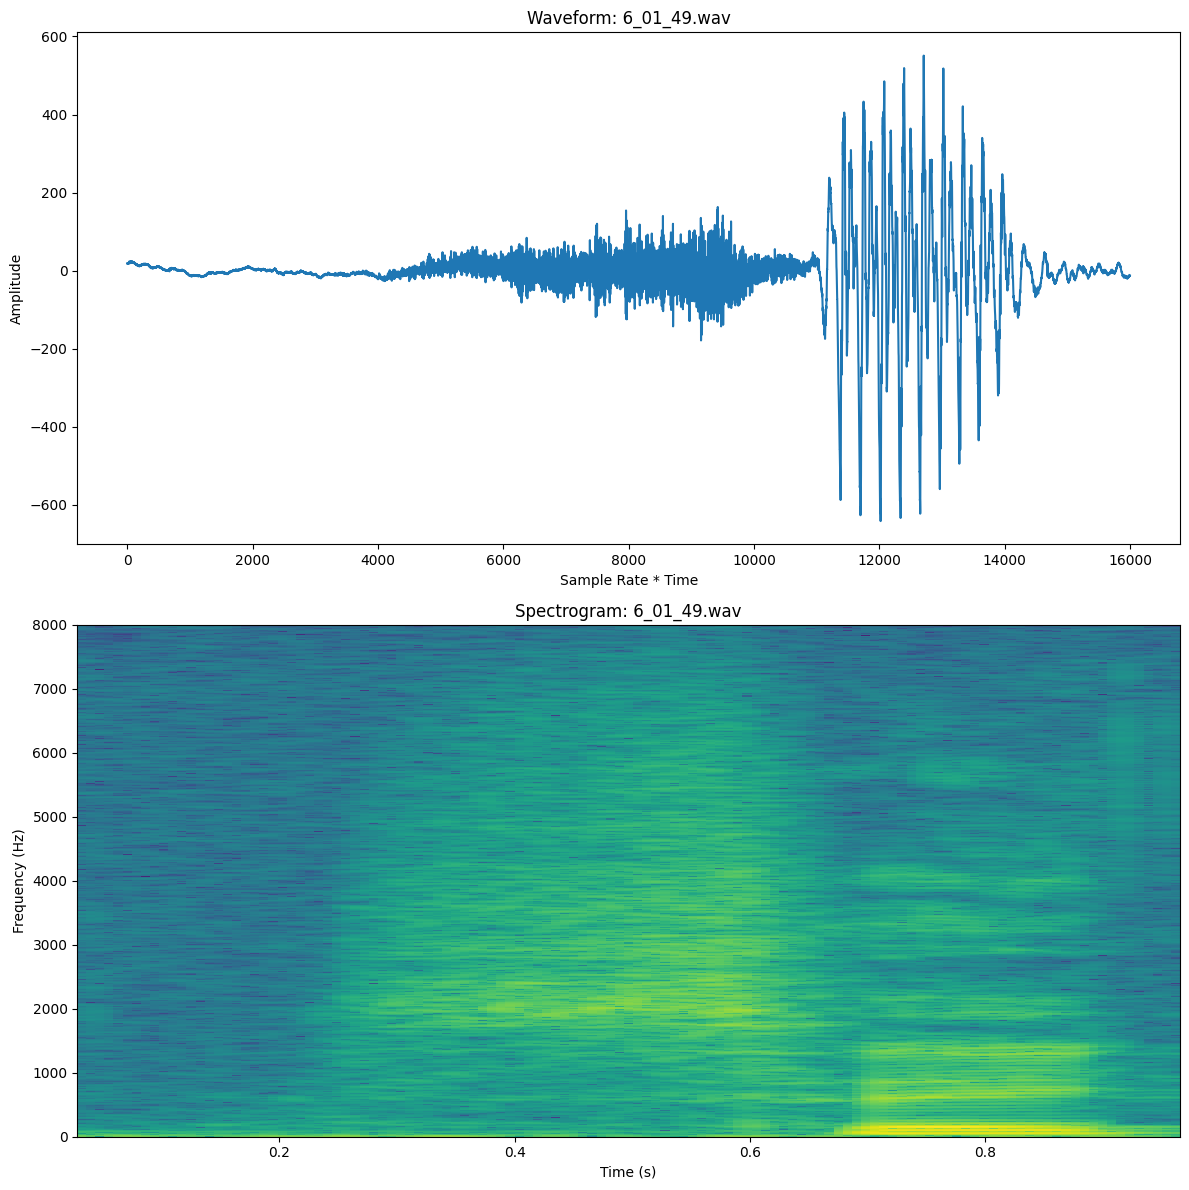

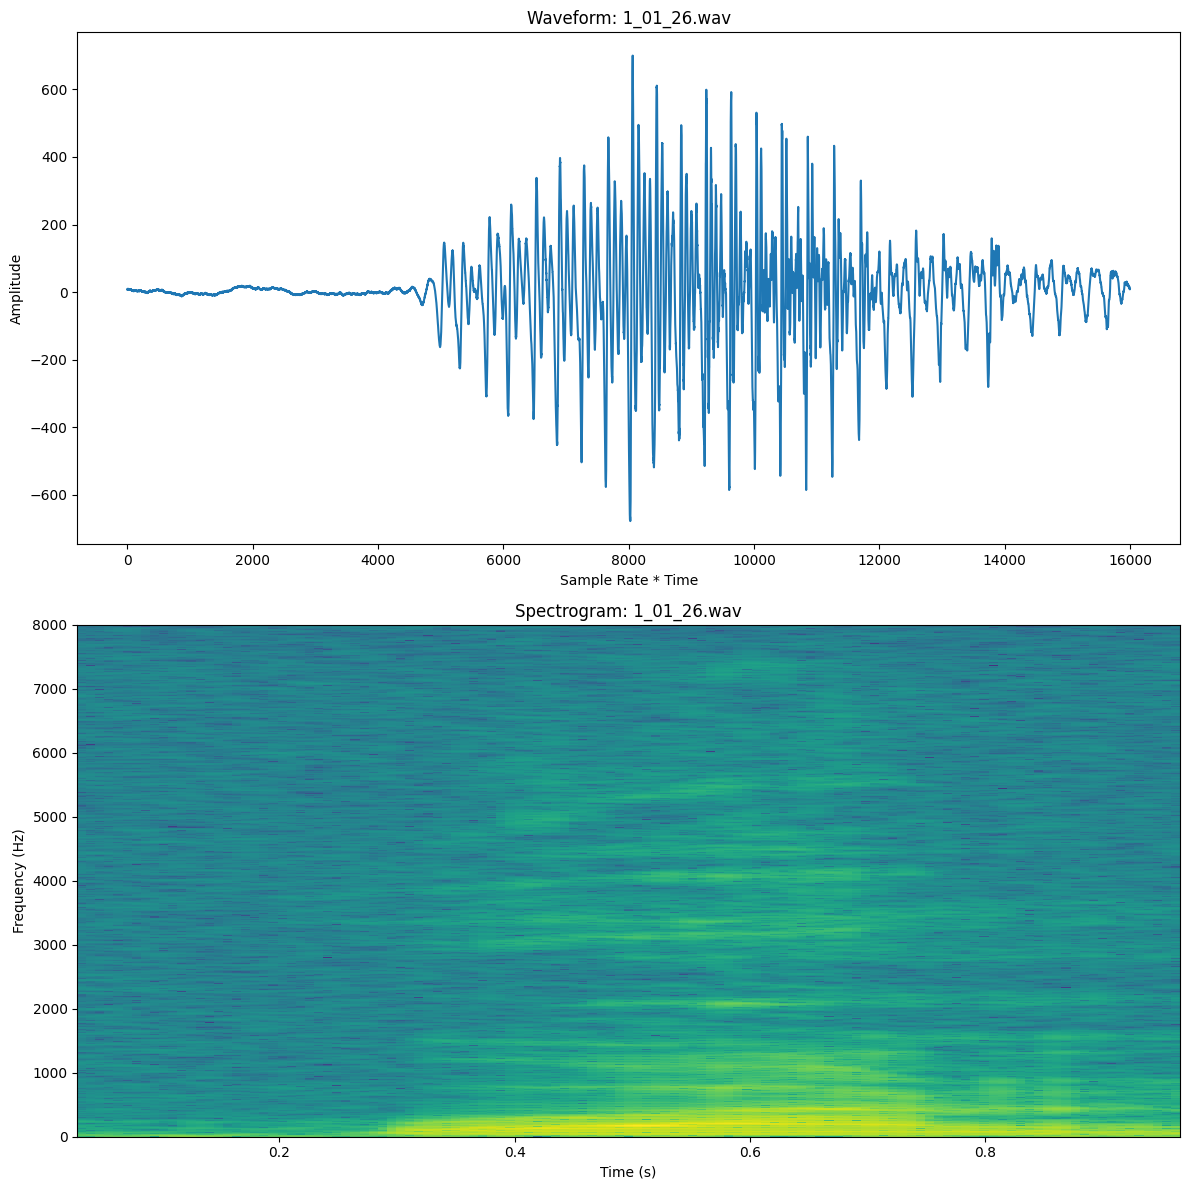

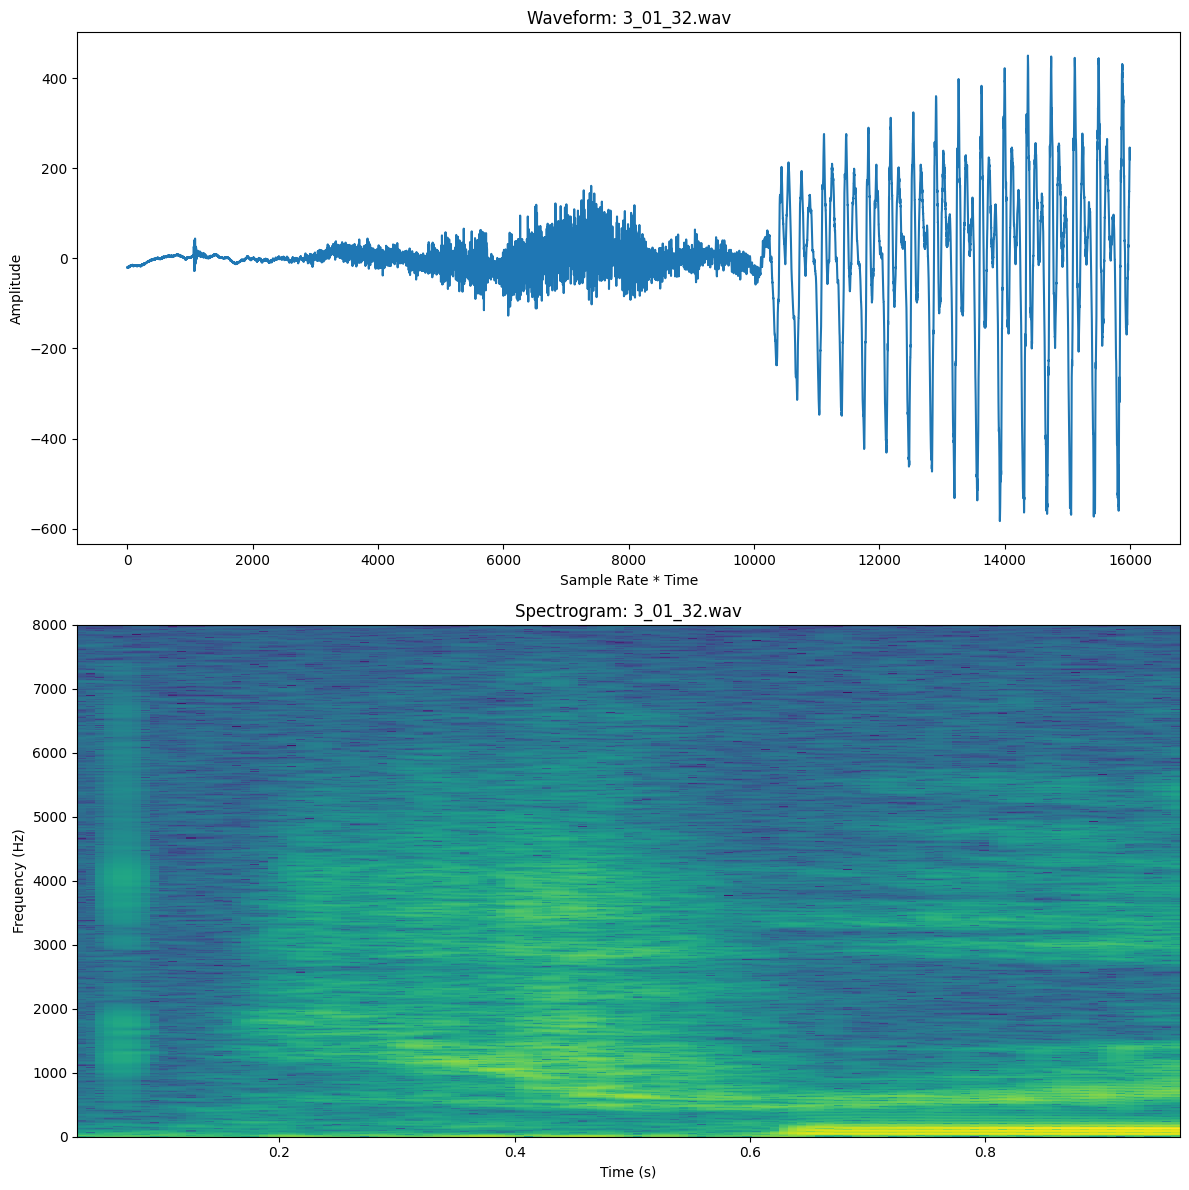

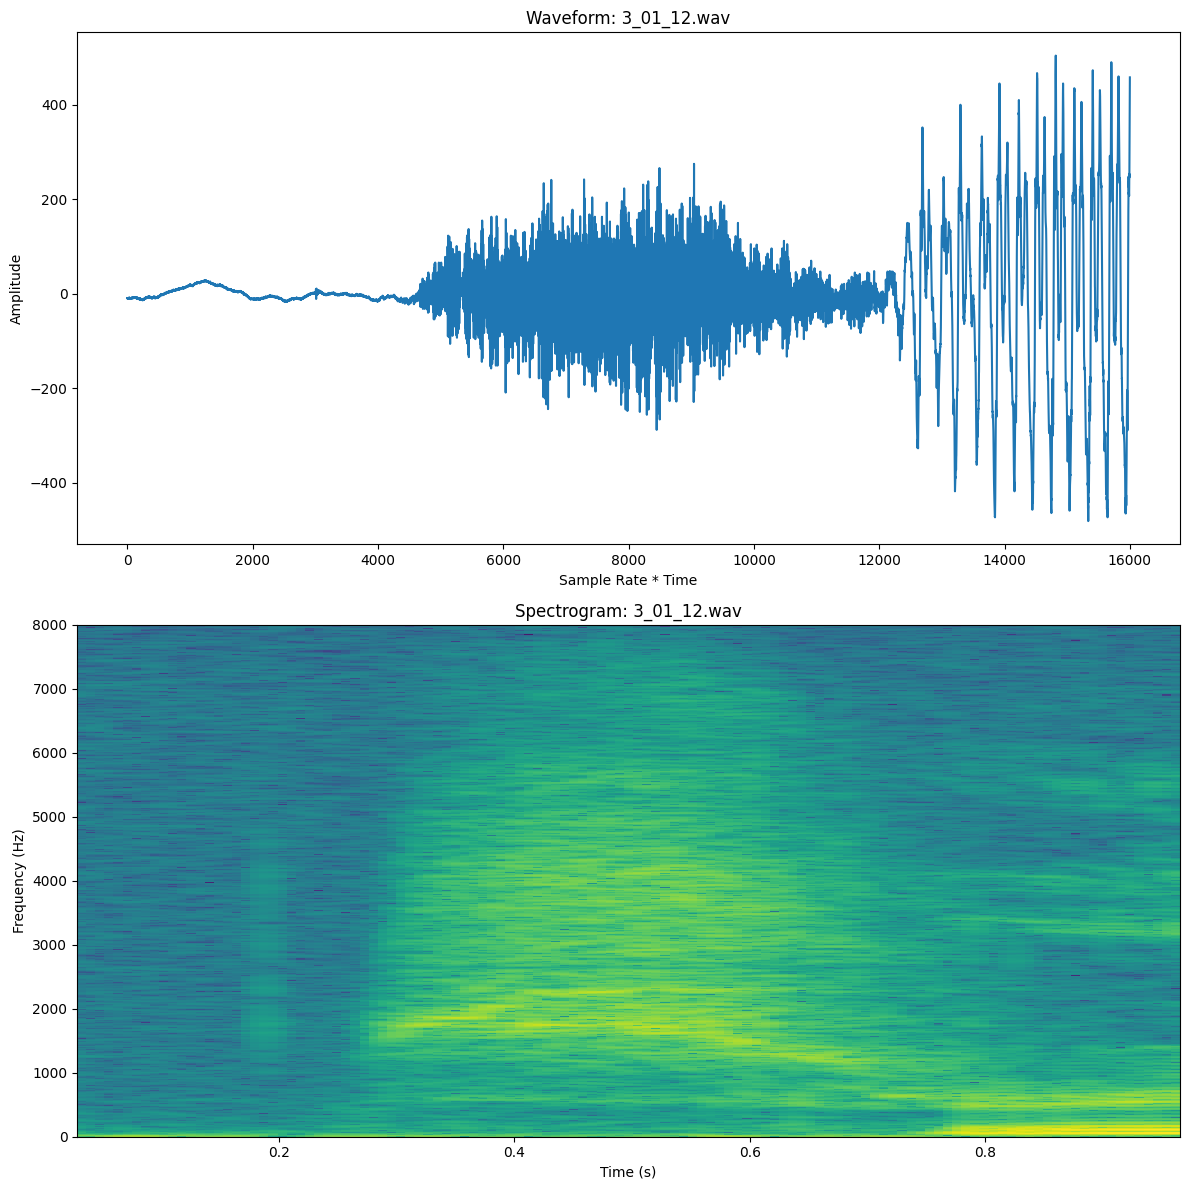

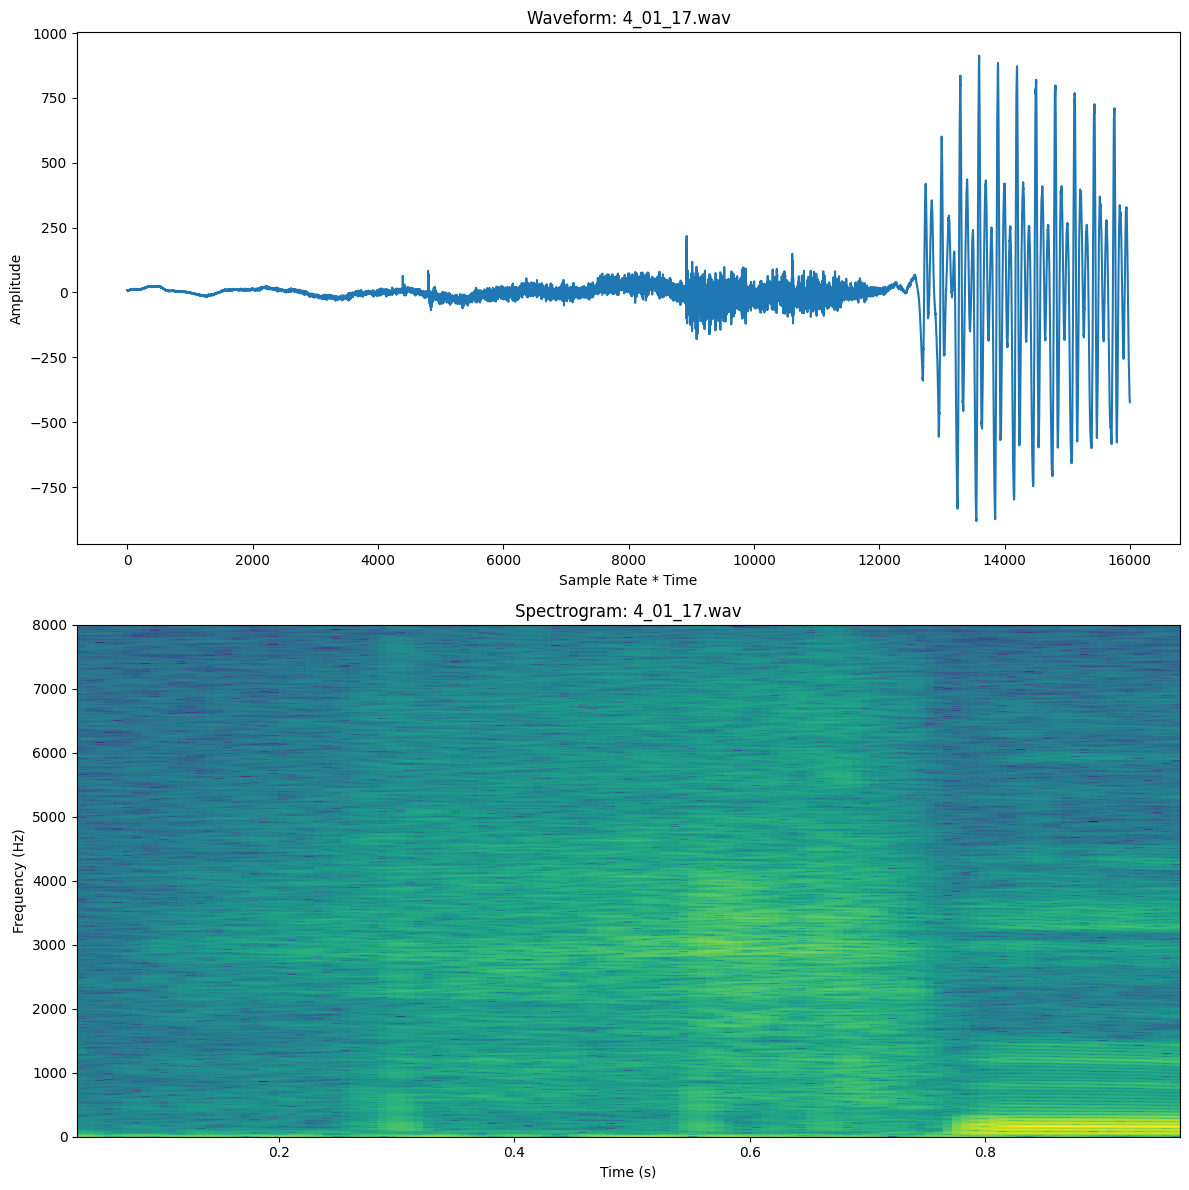

In [6]:
parent_list = []
for folder in sorted(os.listdir(dataset_path))[:5]:
    folder_path = os.path.join(dataset_path, folder)
    for file in os.listdir(folder_path):
        if file.endswith(".wav") and "_noisy" not in file:
            parent_list.append(os.path.join(folder_path, file))
    if len(parent_list) >= 5:
        break

# Plot waveform and spectrogram for the first 5 files
for i in range(min(5, len(parent_list))):
    signal_wave = wave.open(parent_list[i], 'r')
    sample_rate = 16000  # Assuming 16kHz sample rate
    sig = np.frombuffer(signal_wave.readframes(sample_rate), dtype=np.int16)

    plt.figure(figsize=(12, 12))

    plt.subplot(211)
    plt.title(f"Waveform: {os.path.basename(parent_list[i])}")
    plt.plot(sig)
    plt.xlabel('Sample Rate * Time')
    plt.ylabel('Amplitude')

    plt.subplot(212)
    plt.specgram(sig, NFFT=1024, Fs=sample_rate, noverlap=900)
    plt.title(f"Spectrogram: {os.path.basename(parent_list[i])}")
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')

    plt.tight_layout()
    plt.show()

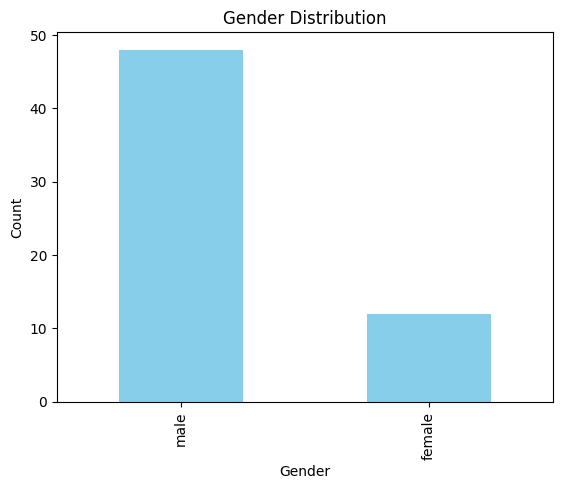

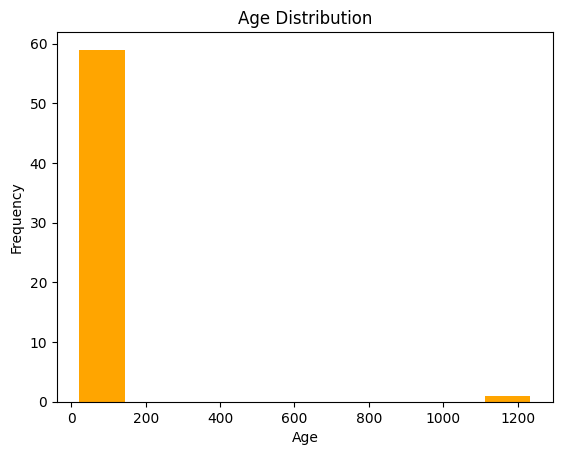

In [7]:
# Gender distribution
gender_counts = metadata_df['gender'].value_counts()
gender_counts.plot(kind='bar', title='Gender Distribution', color='skyblue')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Age distribution
metadata_df['age'] = pd.to_numeric(metadata_df['age'], errors='coerce')  # Convert age to numeric
metadata_df['age'].plot(kind='hist', bins=10, title='Age Distribution', color='orange')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Valid Pairs: 30000


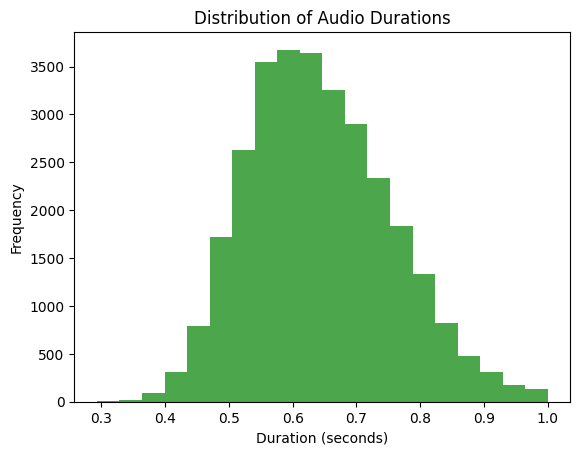

Unique Sampling Rates: {48000}


In [27]:
valid_pairs = paired_data_df.dropna(subset=['Clean', 'Noisy'])
print(f"Valid Pairs: {len(valid_pairs)}")

# Analyze durations and sampling rates for valid pairs
durations = []
sampling_rates = []

for path in valid_pairs['Clean']:
    y, sr = librosa.load(path, sr=None)  # Load with original sampling rate
    durations.append(librosa.get_duration(y=y, sr=sr))
    sampling_rates.append(sr)

plt.hist(durations, bins=20, color='green', alpha=0.7)
plt.title('Distribution of Audio Durations')
plt.xlabel('Duration (seconds)')
plt.ylabel('Frequency')
plt.show()

unique_sampling_rates = set(sampling_rates)
print(f"Unique Sampling Rates: {unique_sampling_rates}")

# Preprocess

In [ ]:
# List of speaker IDs
speaker_folders = [f for f in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, f))]
speaker_folders.sort()

In [ ]:
def create_paired_file_list_all_speakers():
    paired_files = []
    for speaker in speaker_folders:
        speaker_path = os.path.join(dataset_path, speaker)
        files = os.listdir(speaker_path)
        clean_files = [f for f in files if f.endswith('.wav') and '_noisy' not in f]
        for clean_file in clean_files:
            base_name = clean_file.replace('.wav', '')
            noisy_file = f"{base_name}_noisy.wav"
            clean_path = os.path.join(speaker_path, clean_file)
            noisy_path = os.path.join(speaker_path, noisy_file)
            if os.path.exists(noisy_path):
                digit = base_name.split('_')[0]
                paired_files.append({
                    'Clean_Path': clean_path,
                    'Noisy_Path': noisy_path,
                    'Digit': digit,
                    'Speaker_ID': speaker
                })
    return paired_files

In [11]:
# Collect all paired files
all_paired_files = create_paired_file_list_all_speakers()
print(f"Total samples: {len(all_paired_files)}")

Total samples: 30000


In [12]:
# Shuffle and split
random.seed(42)
train_files, remaining_files = train_test_split(all_paired_files, test_size=0.2, random_state=42)
val_files, test_files = train_test_split(remaining_files, test_size=0.5, random_state=42)

print(f"Training samples: {len(train_files)}")
print(f"Validation samples: {len(val_files)}")
print(f"Test samples: {len(test_files)}")

Training samples: 24000
Validation samples: 3000
Test samples: 3000


## Functions

In [13]:
def plot_mel_spectrograms(sample, sample_rate, hop_length):
    """
    Plot the noisy and clean mel spectrograms for a given sample.
    """
    noisy_spec = sample[0].numpy()
    clean_spec = sample[1].numpy()

    # Plot spectrograms
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(noisy_spec, sr=sample_rate, hop_length=hop_length,
                             x_axis='time', y_axis='mel')
    plt.title('Noisy Mel Spectrogram')
    plt.colorbar(format='%+2.0f dB')

    plt.subplot(1, 2, 2)
    librosa.display.specshow(clean_spec, sr=sample_rate, hop_length=hop_length,
                             x_axis='time', y_axis='mel')
    plt.title('Clean Mel Spectrogram')
    plt.colorbar(format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

In [14]:
def plot_random_samples(all_clean, all_noisy, all_denoised, global_std, global_mean, num_samples=3, sr=22050, hop_length=512, figsize=(15, 4)):
    """
    Plots random samples of noisy, denoised, and clean spectrograms.

    """
    
    indices = random.sample(range(len(all_clean)), num_samples)
    
    for idx in indices:
        # Extract spectrogram batches
        clean_batch = all_clean[idx]
        noisy_batch = all_noisy[idx]
        denoised_batch = all_denoised[idx]

        batch_size = clean_batch.shape[0]
        sample_idx = random.randint(0, batch_size - 1)
        
        clean_spec = clean_batch[sample_idx]
        noisy_spec = noisy_batch[sample_idx]
        denoised_spec = denoised_batch[sample_idx]
        
        if isinstance(clean_spec, torch.Tensor):
            clean_spec = clean_spec.squeeze().detach().cpu().numpy()
        else:
            clean_spec = np.squeeze(clean_spec)
        
        if isinstance(noisy_spec, torch.Tensor):
            noisy_spec = noisy_spec.squeeze().detach().cpu().numpy()
        else:
            noisy_spec = np.squeeze(noisy_spec)
        
        if isinstance(denoised_spec, torch.Tensor):
            denoised_spec = denoised_spec.squeeze().detach().cpu().numpy()
        else:
            denoised_spec = np.squeeze(denoised_spec)

        if clean_spec.ndim != 2:
            raise ValueError(f'clean_spec has invalid shape: {clean_spec.shape}')
        if noisy_spec.ndim != 2:
            raise ValueError(f'noisy_spec has invalid shape: {noisy_spec.shape}')
        if denoised_spec.ndim != 2:
            raise ValueError(f'denoised_spec has invalid shape: {denoised_spec.shape}')
        
        # Undo normalization
        clean_spec = clean_spec * global_std + global_mean
        noisy_spec = noisy_spec * global_std + global_mean
        denoised_spec = denoised_spec * global_std + global_mean
        
        plt.figure(figsize=figsize)
        
        plt.subplot(1, 3, 1)
        librosa.display.specshow(noisy_spec, sr=sr, hop_length=hop_length, 
                                 x_axis='time', y_axis='mel')
        plt.title('Noisy Input')
        plt.colorbar(format='%+2.0f dB')
        
        plt.subplot(1, 3, 2)
        librosa.display.specshow(denoised_spec, sr=sr, hop_length=hop_length, 
                                 x_axis='time', y_axis='mel')
        plt.title('Denoised Output')
        plt.colorbar(format='%+2.0f dB')
        
        plt.subplot(1, 3, 3)
        librosa.display.specshow(clean_spec, sr=sr, hop_length=hop_length, 
                                 x_axis='time', y_axis='mel')
        plt.title('Clean Target')
        plt.colorbar(format='%+2.0f dB')
        
        plt.tight_layout()
        plt.show()

In [15]:
def reconstruct_audio(sample, global_mean, global_std, sample_rate=22050, n_fft=2048, hop_length=512, is_clean=True):
    """
    Reconstruct and save audio from a given dataset sample.
    """
    
    # Unpack sample
    noisy_spec, clean_spec, clean_path, noisy_path, clean_stretch_factor, noisy_stretch_factor = sample
    
    # Select spectrogram and stretch factor based on `is_clean`
    spec = clean_spec if is_clean else noisy_spec
    stretch_factor = clean_stretch_factor if is_clean else noisy_stretch_factor
    output_filename = 'reconstructed_clean_audio.wav' if is_clean else 'reconstructed_noisy_audio.wav'

    # Step 1: Reverse normalization of Mel spectrogram
    spec = spec.numpy()
    mel_spec_db = (spec * global_std) + global_mean

    # Step 2: Convert Mel spectrogram to power
    mel_spec_power = librosa.db_to_power(mel_spec_db)

    # Step 3: Convert Mel spectrogram to STFT spectrogram
    stft_spec = librosa.feature.inverse.mel_to_stft(mel_spec_power, sr=sample_rate, n_fft=n_fft)

    # Step 4: Reconstruct waveform using Griffin-Lim
    reconstructed_waveform = librosa.griffinlim(stft_spec, hop_length=hop_length, n_iter=32)

    # Step 5: Reverse time-stretching to original length
    original_waveform = librosa.effects.time_stretch(reconstructed_waveform, rate=1 / stretch_factor)

    # Step 6: Save the reconstructed audio
    sf.write(output_filename, original_waveform, sample_rate)

    # Step 7: Visualize the waveform
    plt.figure(figsize=(10, 4))
    librosa.display.waveshow(original_waveform, sr=sample_rate)
    plt.title("Reconstructed Original Waveform")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.show()

    print(f"Reconstructed audio saved as '{output_filename}'")

In [16]:
def reconstruct_random_sample(model, test_dataset, global_mean, global_std, device, sample_rate=22050, n_fft=2048, hop_length=512):
    model.eval()
    
    idx = random.randint(0, len(test_dataset) - 1)
    
    sample = test_dataset[idx]
    noisy_spec, clean_spec, clean_path, noisy_path, clean_stretch_factor, noisy_stretch_factor = sample
    
    noisy_spec = noisy_spec.to(device)
    clean_spec = clean_spec.to(device)
    
    if noisy_spec.dim() == 2:
        noisy_spec = noisy_spec.unsqueeze(0).unsqueeze(0)
    elif noisy_spec.dim() == 3:
        noisy_spec = noisy_spec.unsqueeze(0)
    
    if clean_spec.dim() == 2:
        clean_spec = clean_spec.unsqueeze(0).unsqueeze(0)
    elif clean_spec.dim() == 3:
        clean_spec = clean_spec.unsqueeze(0)
    
    with torch.no_grad():
        denoised_spec = model(noisy_spec)
        denoised_spec = denoised_spec.squeeze(0).squeeze(0)
    
    noisy_spec = noisy_spec.squeeze(0).squeeze(0)
    clean_spec = clean_spec.squeeze(0).squeeze(0)
    
    for spec, title, filename, stretch_factor in zip(
        [noisy_spec, clean_spec, denoised_spec],
        ["Noisy", "Clean", "Denoised"],
        ["reconstructed_noisy_audio.wav", "reconstructed_clean_audio.wav", "reconstructed_denoised_audio.wav"],
        [noisy_stretch_factor, clean_stretch_factor, clean_stretch_factor]  # Use clean stretch factor for denoised
    ):
        spec = spec.cpu().numpy()
        mel_spec_db = (spec * global_std) + global_mean
        
        mel_spec_power = librosa.db_to_power(mel_spec_db)
        
        stft_spec = librosa.feature.inverse.mel_to_stft(mel_spec_power, sr=sample_rate, n_fft=n_fft)
        
        reconstructed_waveform = librosa.griffinlim(stft_spec, hop_length=hop_length, n_iter=32)
        
        original_waveform = librosa.effects.time_stretch(reconstructed_waveform, rate=1 / stretch_factor)
        
        sf.write(filename, original_waveform, sample_rate)
        
        plt.figure(figsize=(10, 4))
        librosa.display.waveshow(original_waveform, sr=sample_rate)
        plt.title(f"{title} Waveform")
        plt.xlabel("Time (s)")
        plt.ylabel("Amplitude")
        plt.show()

        print(f"Reconstructed audio saved as '{filename}'")

In [17]:
def compute_global_mean_std(dataset, batch_size=32, num_workers=NUM_WORKERS):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    sum_ = torch.tensor(0.0, device=device)
    sum_sq = torch.tensor(0.0, device=device)
    total_pixels = 0

    for batch in tqdm(loader, desc='Computing mean and std'):
        noisy_spec, clean_spec, _, _, _, _ = batch
        noisy_spec = noisy_spec.to(device)
        clean_spec = clean_spec.to(device)
        specs = torch.cat([noisy_spec, clean_spec], dim=0)
        total_pixels += specs.numel()

        sum_ += specs.sum()
        sum_sq += (specs ** 2).sum()
        
    mean = sum_.item() / total_pixels
    std = (sum_sq.item() / total_pixels - mean ** 2) ** 0.5
    return mean, std

In [18]:
def compute_snr(original, reconstructed):
    signal_power = np.mean(original ** 2)
    noise_power = np.mean((original - reconstructed) ** 2)
    snr = 10 * np.log10(signal_power / (noise_power + 1e-8))
    return snr

**How SNR is computed here:** `compute_snr` compares the *z-normalised log-mel spectrograms*, not the
waveforms. `SNR = 10·log10(mean(clean²) / mean((clean − x)²))`, where `x` is the noisy input or the denoised
output. The values are useful for comparing models with each other, but they are not the same as a
conventional waveform SNR in dB.

In [19]:
def compute_average_snr(all_noisy, all_clean, all_denoised, compute_snr):
    """
    Compute the average SNR for noisy and denoised signals and their improvement.
    """
    
    all_noisy = np.concatenate(all_noisy, axis=0)
    all_clean = np.concatenate(all_clean, axis=0)
    all_denoised = np.concatenate(all_denoised, axis=0)

    # Compute SNR for noisy and denoised signals
    snr_noisy = []
    snr_denoised = []

    for i in range(len(all_clean)):
        clean = all_clean[i]
        noisy = all_noisy[i]
        denoised = all_denoised[i]
        
        snr_noisy.append(compute_snr(clean, noisy))
        snr_denoised.append(compute_snr(clean, denoised))

    average_snr_noisy = np.mean(snr_noisy)
    average_snr_denoised = np.mean(snr_denoised)
    snr_improvement = average_snr_denoised - average_snr_noisy

    print(f"Average Noisy SNR: {average_snr_noisy:.2f} dB")
    print(f"Average Denoised SNR: {average_snr_denoised:.2f} dB")
    print(f"SNR Improvement: {snr_improvement:.2f} dB")

    return {
        "average_noisy_snr": average_snr_noisy,
        "average_denoised_snr": average_snr_denoised,
        "snr_improvement": snr_improvement
    }

## Prepare data for training

In [20]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [21]:
class AudioDataset(Dataset):
    def __init__(self, file_list, sample_rate=22050, n_mels=128, n_fft=2048, hop_length=512, max_length=128, augmentation=False, global_mean=0.0, global_std=1.0):
        self.file_list = file_list
        self.sample_rate = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.max_length = max_length
        self.augmentation = augmentation
        self.global_mean = global_mean
        self.global_std = global_std

        self.target_length = self.max_length * self.hop_length

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        sample_info = self.file_list[idx]  # Access metadata
        clean_path = sample_info['Clean_Path']
        noisy_path = sample_info['Noisy_Path']

        # Load audio files
        clean_waveform, _ = librosa.load(clean_path, sr=self.sample_rate)
        noisy_waveform, _ = librosa.load(noisy_path, sr=self.sample_rate)

        # Stretch waveforms to ensure consistent length
        clean_stretch_factor = len(clean_waveform) / self.target_length
        noisy_stretch_factor = len(noisy_waveform) / self.target_length

        clean_waveform = self.stretch_waveform(clean_waveform, self.target_length)
        noisy_waveform = self.stretch_waveform(noisy_waveform, self.target_length)

        # Data augmentation (if enabled)
        if self.augmentation:
            noisy_waveform = self.add_synthetic_noise(noisy_waveform)

        # Generate mel spectrograms
        clean_spec = self.process_waveform(clean_waveform)
        noisy_spec = self.process_waveform(noisy_waveform)

        # Return spectrograms, stretch factors, and file paths
        return noisy_spec, clean_spec, clean_path, noisy_path, clean_stretch_factor , noisy_stretch_factor

    def process_waveform(self, waveform):
        # Generate Mel spectrogram
        mel_spec = librosa.feature.melspectrogram(y=waveform, sr=self.sample_rate, n_fft=self.n_fft,
                                                  hop_length=self.hop_length, n_mels=self.n_mels)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Normalize using global mean and std
        mel_spec_db_normalized = (mel_spec_db - self.global_mean) / self.global_std

        # Convert to tensor and add channel dimension
        mel_spec_tensor = torch.tensor(mel_spec_db_normalized, dtype=torch.float32).unsqueeze(0)  # Shape: (1, n_mels, time_steps)
    
        # Resize spectrogram to fixed size
        mel_spec_resized = F.interpolate(mel_spec_tensor.unsqueeze(0), size=(128, 128), mode='bilinear', align_corners=False).squeeze(0)
        
        return mel_spec_resized.squeeze(0)

    def stretch_waveform(self, waveform, target_length):
        current_length = len(waveform)
        if current_length != target_length:

            stretch_factor = current_length / target_length
            waveform = librosa.effects.time_stretch(waveform, rate=stretch_factor)

            waveform = waveform[:target_length] if len(waveform) > target_length else np.pad(waveform, (0, target_length - len(waveform)), mode='constant', constant_values=0)
        return waveform

    def add_synthetic_noise(self, waveform, noise_factor=0.005):
        noise = np.random.normal(0, 1, len(waveform))
        augmented_waveform = waveform + noise_factor * noise
        return np.clip(augmented_waveform, -1.0, 1.0)

In [22]:
# Create the training dataset without augmentation for accurate statistics
train_dataset_for_stats = AudioDataset(train_files, augmentation=False)

# Compute global mean and std
global_mean, global_std = compute_global_mean_std(train_dataset_for_stats)
print(f"Global Mean: {global_mean}, Global Std: {global_std}")

Computing mean and std: 100%|██████████| 750/750 [37:25<00:00,  2.99s/it]

Global Mean: -53.52386979166667, Global Std: 14.138942529695965


In [23]:
# Create datasets
train_dataset = AudioDataset(train_files, global_mean=global_mean, global_std=global_std)
val_dataset = AudioDataset(val_files, global_mean=global_mean, global_std=global_std)
test_dataset = AudioDataset(test_files, global_mean=global_mean, global_std=global_std)

BATCH_SIZE = 8 if QUICK_RUN else 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

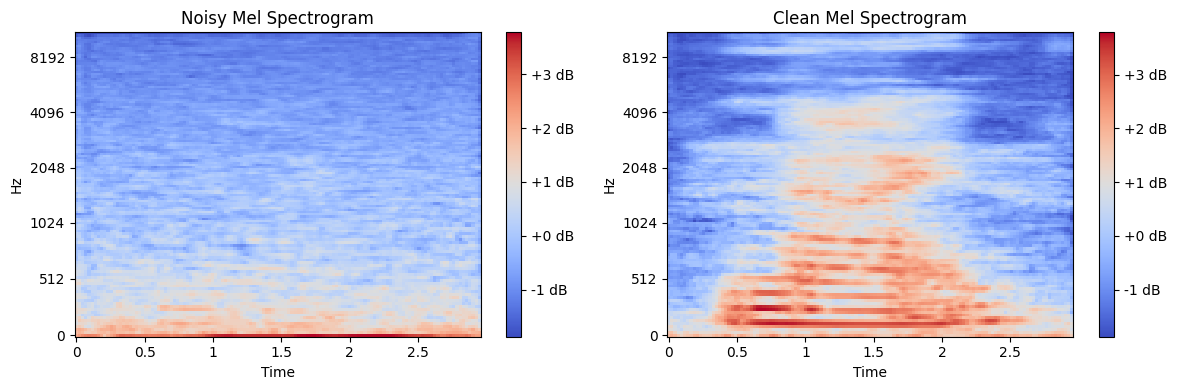

In [24]:
sample = train_dataset[1]
plot_mel_spectrograms(sample, train_dataset.sample_rate, train_dataset.hop_length)

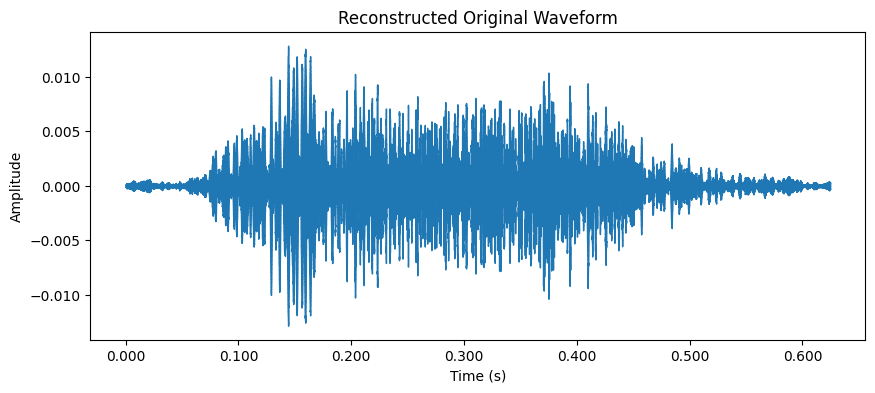

Reconstructed audio saved as 'reconstructed_clean_audio.wav'


In [25]:
sample = train_dataset[1]
reconstruct_audio(sample, global_mean=global_mean, global_std=global_std, is_clean=True)

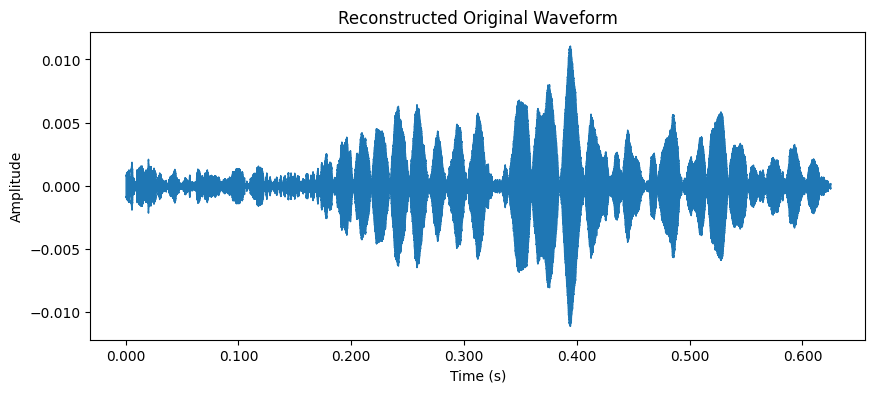

Reconstructed audio saved as 'reconstructed_noisy_audio.wav'


In [26]:
reconstruct_audio(sample, global_mean=global_mean, global_std=global_std, is_clean=False)

# Model

In [28]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs, device):
    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        train_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Training]')
        for noisy, clean , *_ in train_bar:
            noisy = noisy.unsqueeze(1).to(device)
            clean = clean.unsqueeze(1).to(device)

            optimizer.zero_grad()
            outputs = model(noisy)
            loss = criterion(outputs, clean)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * noisy.size(0)
            train_bar.set_postfix(loss=loss.item())

        epoch_train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)

        model.eval()
        val_running_loss = 0.0
        val_bar = tqdm(val_loader, desc=f'Epoch {epoch+1}/{num_epochs} [Validation]', leave=False)
        with torch.no_grad():
            for noisy, clean , *_ in val_bar:
                noisy = noisy.unsqueeze(1).to(device)
                clean = clean.unsqueeze(1).to(device)

                outputs = model(noisy)
                loss = criterion(outputs, clean)

                val_running_loss += loss.item() * noisy.size(0)
                val_bar.set_postfix(loss=loss.item())

        epoch_val_loss = val_running_loss / len(val_loader.dataset)
        val_losses.append(epoch_val_loss)

        print(f"Epoch [{epoch+1}/{num_epochs}], "
              f"Train Loss: {epoch_train_loss:.4f}, "
              f"Val Loss: {epoch_val_loss:.4f}")

        scheduler.step()

    return train_losses, val_losses

def evaluate_model(model, data_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_noisy = []
    all_clean = []
    all_denoised = []

    eval_bar = tqdm(data_loader, desc='Evaluating')
    with torch.no_grad():
        for noisy, clean , *_ in eval_bar:
            noisy = noisy.unsqueeze(1).to(device)
            clean = clean.unsqueeze(1).to(device)

            outputs = model(noisy)
            loss = criterion(outputs, clean)

            running_loss += loss.item() * noisy.size(0)
            eval_bar.set_postfix(loss=loss.item())

            # Collect data for SNR calculation
            all_noisy.append(noisy.cpu().numpy())
            all_clean.append(clean.cpu().numpy())
            all_denoised.append(outputs.cpu().numpy())

    average_loss = running_loss / len(data_loader.dataset)
    print(f"Average Loss: {average_loss:.4f}")

    return average_loss, all_noisy, all_clean, all_denoised

In [30]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super(DenoisingAutoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((16, 16)),
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(256, 128 * 16 * 16),
            nn.Unflatten(1, (128, 16, 16)),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed

**Design note:** this baseline ends in a `Sigmoid`, so its output is limited to `[0, 1]`, while the
z-normalised target spectrograms also contain many negative values. It also squeezes every spectrogram
through a 256-dimensional bottleneck, without skip connections. Both limit how closely it can reproduce the
target. The U-Net below has neither restriction.

## Train

In [31]:
model = DenoisingAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = StepLR(optimizer, step_size=5, gamma=0.1)

NUM_EPOCHS = 1 if QUICK_RUN else 10

# Train the model
train_losses, val_losses = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, device)

Epoch 1/10 [Training]: 100%|██████████| 750/750 [34:46<00:00,  2.78s/it, loss=0.801]


Epoch [1/10], Train Loss: 0.8028, Val Loss: 0.7530


Epoch 2/10 [Training]: 100%|██████████| 750/750 [34:42<00:00,  2.78s/it, loss=0.716]


Epoch [2/10], Train Loss: 0.7472, Val Loss: 0.7419


Epoch 3/10 [Training]: 100%|██████████| 750/750 [34:45<00:00,  2.78s/it, loss=0.733]


Epoch [3/10], Train Loss: 0.7386, Val Loss: 0.7362


... (10 outputs left out)

Epoch 9/10 [Training]: 100%|██████████| 750/750 [35:02<00:00,  2.80s/it, loss=0.707]


Epoch [9/10], Train Loss: 0.7173, Val Loss: 0.7291


Epoch 10/10 [Training]: 100%|██████████| 750/750 [34:30<00:00,  2.76s/it, loss=0.735]
                                                                                     

Epoch [10/10], Train Loss: 0.7163, Val Loss: 0.7289


## Results

In [32]:
# Evaluate the model on the test set
test_loss, all_noisy, all_clean, all_denoised = evaluate_model(model, test_loader, criterion, device)

Evaluating: 100%|██████████| 94/94 [04:25<00:00,  2.82s/it, loss=0.753]

Average Loss: 0.7347


In [33]:
results = compute_average_snr(all_noisy, all_clean, all_denoised, compute_snr)

Average Noisy SNR: 1.80 dB
Average Denoised SNR: 2.50 dB
SNR Improvement: 0.70 dB


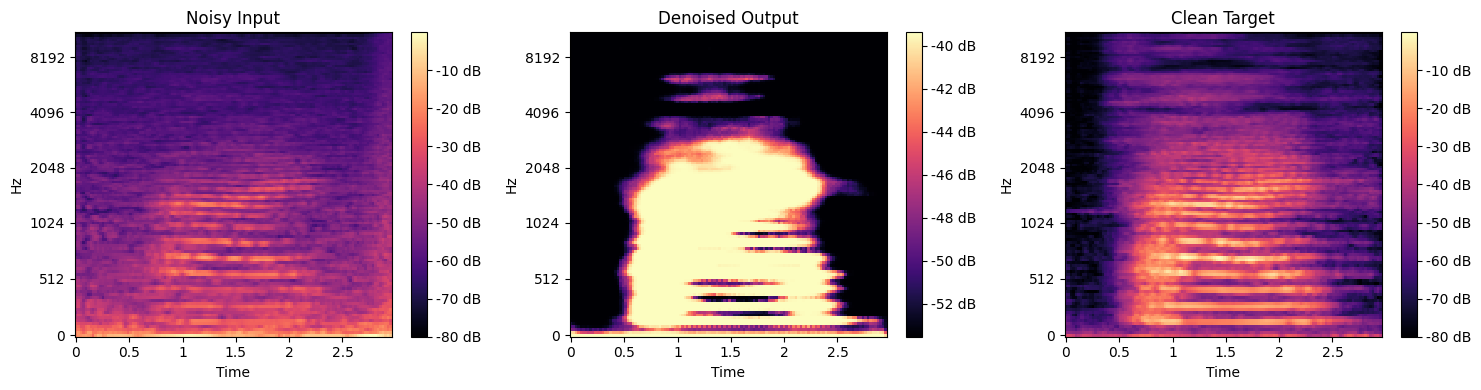

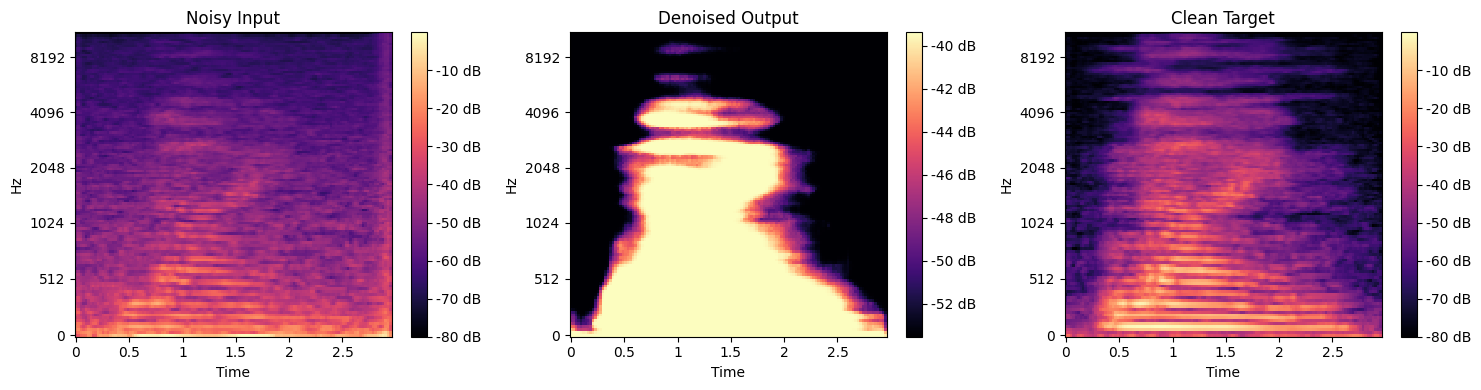

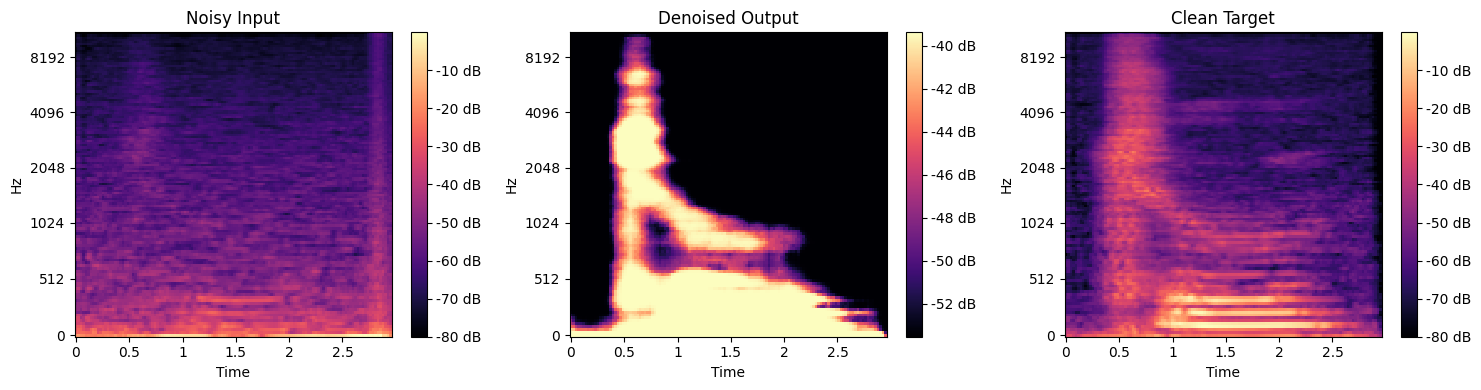

In [50]:
plot_random_samples(all_clean, all_noisy, all_denoised, global_std, global_mean)

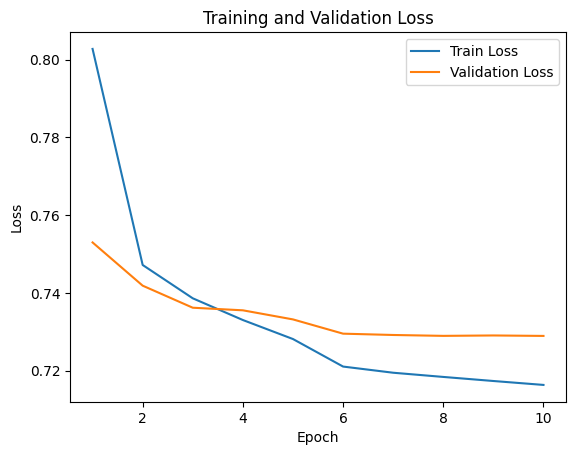

In [41]:
# Plot training and validation loss
plt.figure()
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, label='Train Loss')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

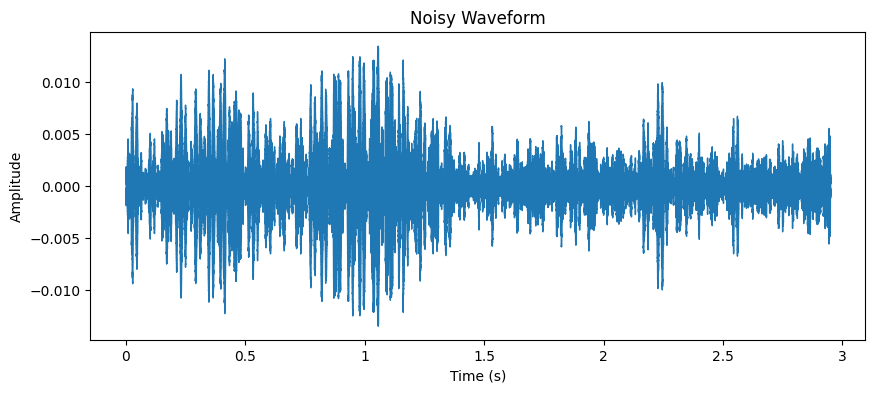

Reconstructed audio saved as 'reconstructed_noisy_audio.wav'


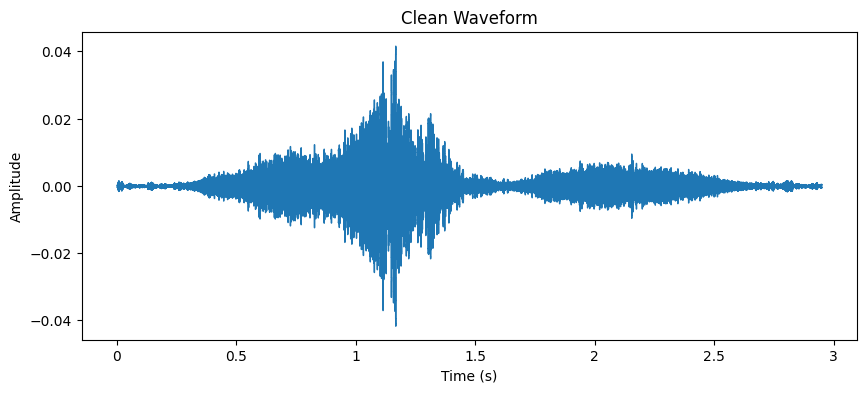

Reconstructed audio saved as 'reconstructed_clean_audio.wav'


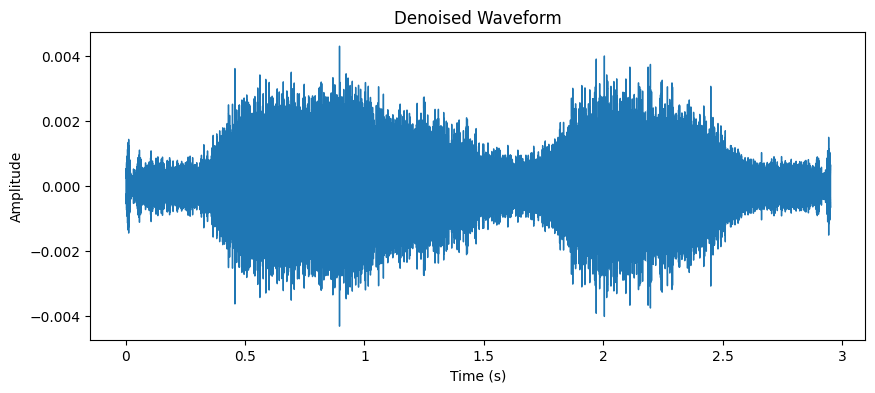

Reconstructed audio saved as 'reconstructed_denoised_audio.wav'


In [59]:
reconstruct_random_sample(
    model=model,
    test_dataset=test_dataset,  # Pass the dataset instead of the loader
    global_mean=global_mean,
    global_std=global_std,
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
)

# Model2

In [29]:
import segmentation_models_pytorch as smp

NUM_EPOCHS = 1 if QUICK_RUN else 5

# Initialize UNet model
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1,
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = StepLR(optimizer, step_size=5, gamma=0.1)

# Train the model
train_losses, val_losses = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, device)

Epoch 1/5 [Training]: 100%|██████████| 750/750 [37:27<00:00,  3.00s/it, loss=0.178]


Epoch [1/5], Train Loss: 0.2209, Val Loss: 0.1779


Epoch 2/5 [Training]: 100%|██████████| 750/750 [37:04<00:00,  2.97s/it, loss=0.151]


Epoch [2/5], Train Loss: 0.1701, Val Loss: 0.1658


Epoch 3/5 [Training]: 100%|██████████| 750/750 [36:52<00:00,  2.95s/it, loss=0.145]


Epoch [3/5], Train Loss: 0.1582, Val Loss: 0.1633


Epoch 4/5 [Training]: 100%|██████████| 750/750 [37:01<00:00,  2.96s/it, loss=0.177]


Epoch [4/5], Train Loss: 0.1501, Val Loss: 0.1720


Epoch 5/5 [Training]: 100%|██████████| 750/750 [37:41<00:00,  3.02s/it, loss=0.153]
                                                                                   

Epoch [5/5], Train Loss: 0.1435, Val Loss: 0.1471


## Results

In [30]:
# Evaluate the model
test_loss, all_noisy, all_clean, all_denoised = evaluate_model(model, test_loader, criterion, device)

Evaluating: 100%|██████████| 94/94 [04:42<00:00,  3.00s/it, loss=0.147]

Average Loss: 0.1485


In [31]:
results = compute_average_snr(all_noisy, all_clean, all_denoised, compute_snr)

Average Noisy SNR: 1.80 dB
Average Denoised SNR: 9.49 dB
SNR Improvement: 7.70 dB


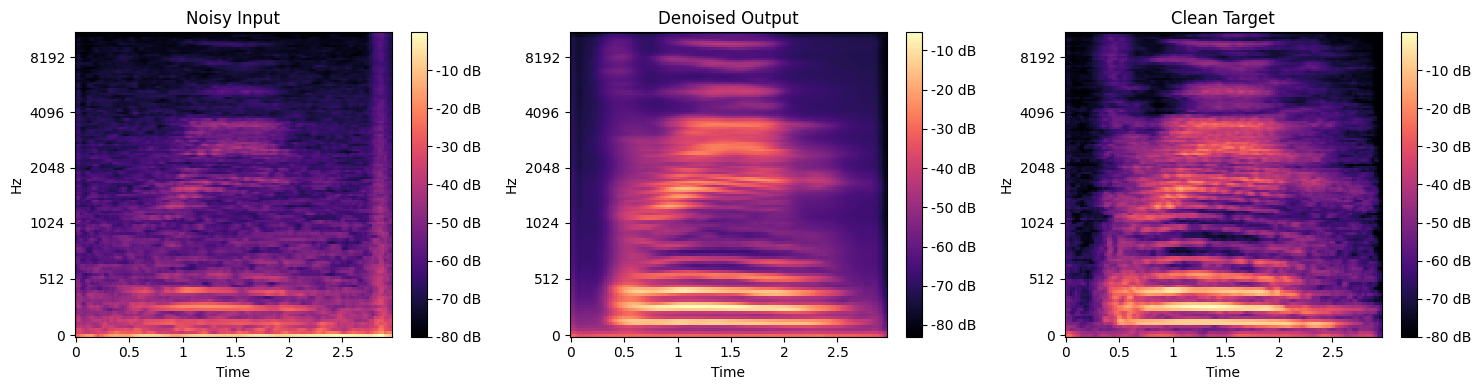

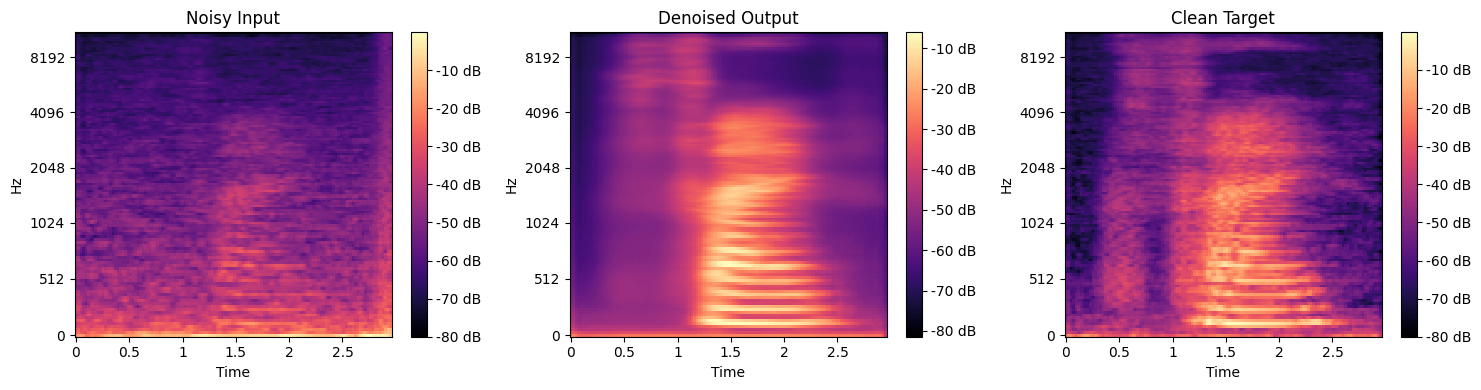

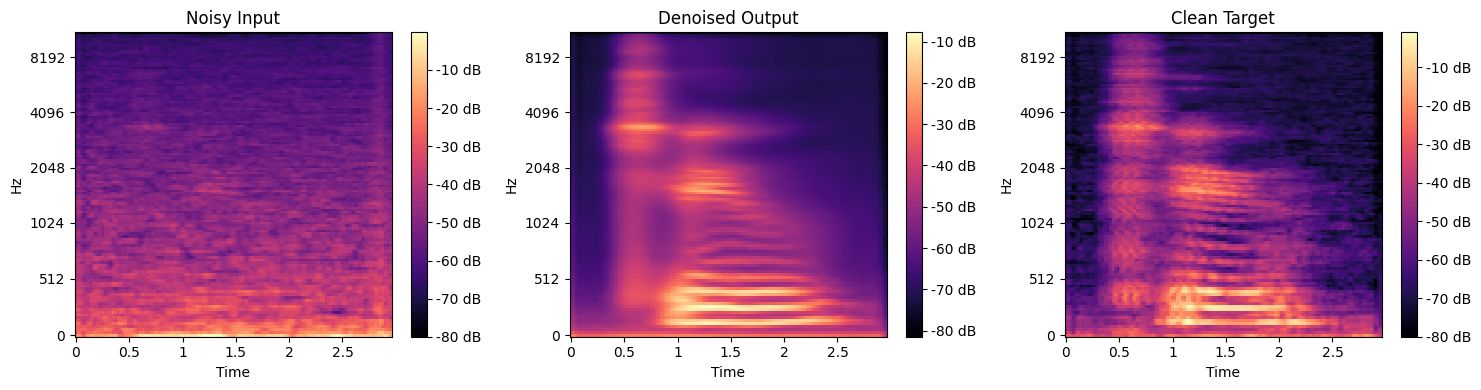

In [32]:
plot_random_samples(all_clean, all_noisy, all_denoised, global_std, global_mean)

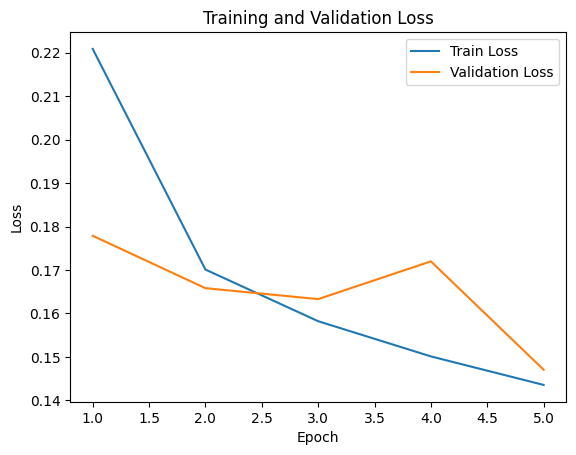

In [33]:
# Plot training and validation loss
plt.figure()
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, label='Train Loss')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

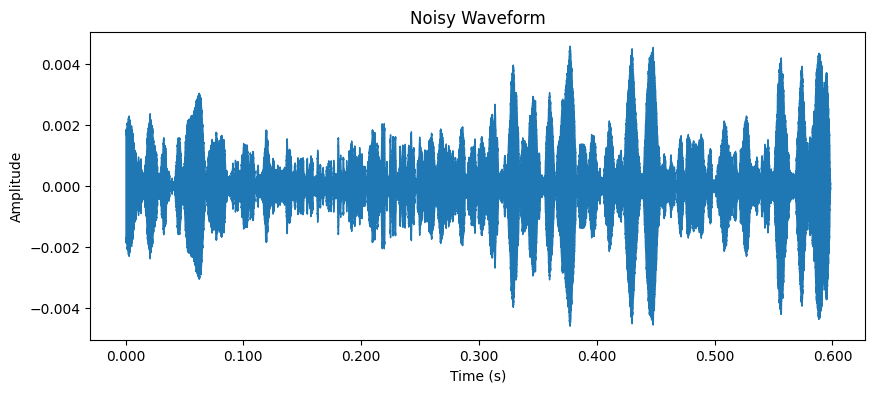

Reconstructed audio saved as 'reconstructed_noisy_audio.wav'


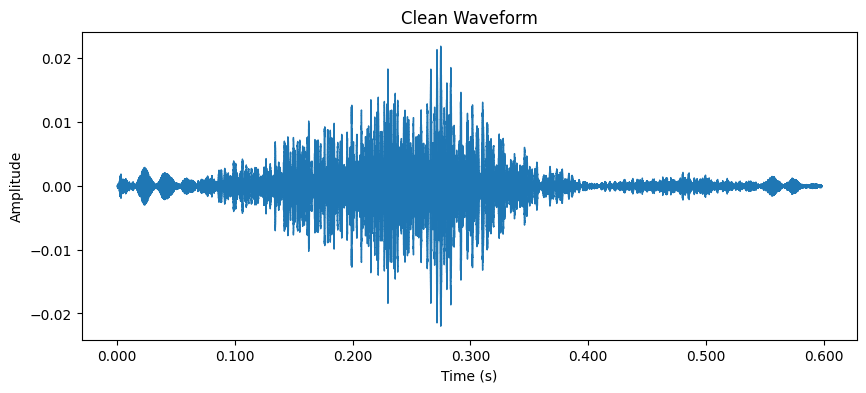

Reconstructed audio saved as 'reconstructed_clean_audio.wav'


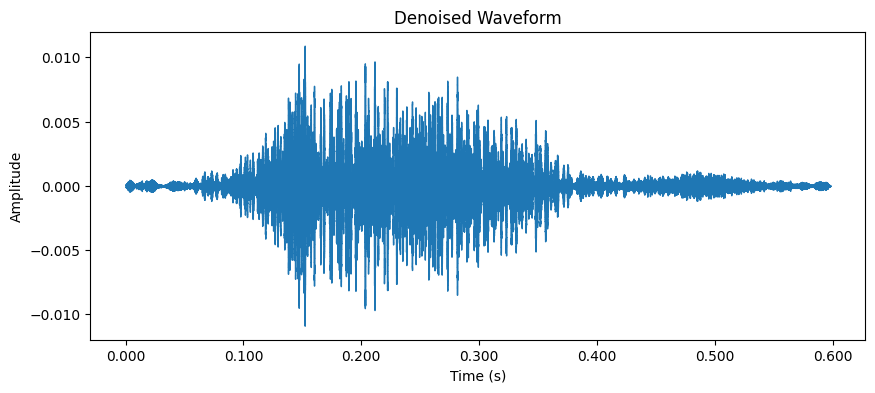

Reconstructed audio saved as 'reconstructed_denoised_audio.wav'


In [34]:
reconstruct_random_sample(
    model=model,
    test_dataset=test_dataset,  # Pass the dataset instead of the loader
    global_mean=global_mean,
    global_std=global_std,
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
)

In [36]:
class AudioDataset(Dataset):
    def __init__(self, file_list, sample_rate=22050, n_mels=128, n_fft=2048, hop_length=512, max_length=128, augmentation=False, global_mean=0.0, global_std=1.0):
        self.file_list = file_list
        self.sample_rate = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.max_length = max_length
        self.augmentation = augmentation
        self.global_mean = global_mean
        self.global_std = global_std

        self.target_length = self.max_length * self.hop_length

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        sample_info = self.file_list[idx]  # Access metadata
        clean_path = sample_info['Clean_Path']
        noisy_path = sample_info['Noisy_Path']
        digit = sample_info['Digit']
        speaker_id = sample_info['Speaker_ID']

        # Load audio files
        clean_waveform, _ = librosa.load(clean_path, sr=self.sample_rate)
        noisy_waveform, _ = librosa.load(noisy_path, sr=self.sample_rate)

        # Stretch waveforms to ensure consistent length
        clean_stretch_factor = len(clean_waveform) / self.target_length
        noisy_stretch_factor = len(noisy_waveform) / self.target_length

        clean_waveform = self.stretch_waveform(clean_waveform, self.target_length)
        noisy_waveform = self.stretch_waveform(noisy_waveform, self.target_length)

        # Data augmentation (if enabled)
        if self.augmentation:
            noisy_waveform = self.add_synthetic_noise(noisy_waveform)

        # Generate mel spectrograms
        clean_spec = self.process_waveform(clean_waveform)
        noisy_spec = self.process_waveform(noisy_waveform)

        # Return spectrograms, stretch factors, and file paths
        return noisy_spec, clean_spec,digit, speaker_id, clean_path, noisy_path, clean_stretch_factor , noisy_stretch_factor

    def process_waveform(self, waveform):
        # Generate Mel spectrogram
        mel_spec = librosa.feature.melspectrogram(y=waveform, sr=self.sample_rate, n_fft=self.n_fft,
                                                  hop_length=self.hop_length, n_mels=self.n_mels)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Normalize using global mean and std
        mel_spec_db_normalized = (mel_spec_db - self.global_mean) / self.global_std

        # Convert to tensor and add channel dimension
        mel_spec_tensor = torch.tensor(mel_spec_db_normalized, dtype=torch.float32).unsqueeze(0) 
    
        # Resize spectrogram to fixed size
        mel_spec_resized = F.interpolate(mel_spec_tensor.unsqueeze(0), size=(128, 128), mode='bilinear', align_corners=False).squeeze(0)
        
        return mel_spec_resized.squeeze(0)

    def stretch_waveform(self, waveform, target_length):
        current_length = len(waveform)
        if current_length != target_length:
            stretch_factor = current_length / target_length
            waveform = librosa.effects.time_stretch(waveform, rate=stretch_factor)
            waveform = waveform[:target_length] if len(waveform) > target_length else np.pad(waveform, (0, target_length - len(waveform)), mode='constant', constant_values=0)
        return waveform

    def add_synthetic_noise(self, waveform, noise_factor=0.005):
        noise = np.random.normal(0, 1, len(waveform))
        augmented_waveform = waveform + noise_factor * noise
        return np.clip(augmented_waveform, -1.0, 1.0)

In [37]:
test_dataset = AudioDataset(test_files, global_mean=global_mean, global_std=global_std)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

In [40]:
def evaluate_model(model, data_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    per_speaker_loss = {}
    per_digit_loss = {}
    speaker_counts = {}
    digit_counts = {}

    eval_bar = tqdm(data_loader, desc='Evaluating')
    with torch.no_grad():
        for noisy, clean, digits, speakers, *_ in eval_bar:
            noisy = noisy.unsqueeze(1).to(device)
            clean = clean.unsqueeze(1).to(device)
            outputs = model(noisy)
            loss = criterion(outputs, clean)
            batch_size = noisy.size(0)

            running_loss += loss.item() * batch_size
            eval_bar.set_postfix(loss=loss.item())

            per_sample_loss = F.mse_loss(outputs, clean, reduction='none')
            per_sample_loss = per_sample_loss.mean(dim=[1, 2, 3])

            for i in range(batch_size):
                speaker = speakers[i]
                digit = digits[i]

                if speaker not in per_speaker_loss:
                    per_speaker_loss[speaker] = 0.0
                    speaker_counts[speaker] = 0
                per_speaker_loss[speaker] += per_sample_loss[i].item()
                speaker_counts[speaker] += 1

                if digit not in per_digit_loss:
                    per_digit_loss[digit] = 0.0
                    digit_counts[digit] = 0
                per_digit_loss[digit] += per_sample_loss[i].item()
                digit_counts[digit] += 1

    avg_per_speaker_loss = {speaker: per_speaker_loss[speaker] / speaker_counts[speaker] for speaker in per_speaker_loss}
    avg_per_digit_loss = {digit: per_digit_loss[digit] / digit_counts[digit] for digit in per_digit_loss}

    average_loss = running_loss / len(data_loader.dataset)
    print(f"Average Loss: {average_loss:.4f}")

    return average_loss, avg_per_speaker_loss, avg_per_digit_loss

In [41]:
test_loss, per_speaker_loss, per_digit_loss = evaluate_model(model, test_loader, criterion, device)

Evaluating: 100%|██████████| 94/94 [04:37<00:00,  2.95s/it, loss=0.147]

Average Loss: 0.1485


In [42]:
# Sort speakers by loss
sorted_speakers = sorted(per_speaker_loss.items(), key=lambda x: x[1])
print("Performance per Speaker:")
for speaker, loss in sorted_speakers:
    print(f"Speaker {speaker}: Loss = {loss:.4f}")

# Sort digits by loss
sorted_digits = sorted(per_digit_loss.items(), key=lambda x: x[1])
print("\nPerformance per Digit:")
for digit, loss in sorted_digits:
    print(f"Digit {digit}: Loss = {loss:.4f}")


Performance per Speaker:
Speaker 09: Loss = 0.1102
Speaker 40: Loss = 0.1133
Speaker 08: Loss = 0.1142
Speaker 37: Loss = 0.1142
Speaker 34: Loss = 0.1152
Speaker 06: Loss = 0.1161
Speaker 27: Loss = 0.1196
Speaker 07: Loss = 0.1204
Speaker 48: Loss = 0.1232
Speaker 12: Loss = 0.1241
Speaker 28: Loss = 0.1245
Speaker 11: Loss = 0.1247
Speaker 16: Loss = 0.1250
Speaker 31: Loss = 0.1268
Speaker 05: Loss = 0.1290
Speaker 14: Loss = 0.1297
Speaker 41: Loss = 0.1308
Speaker 42: Loss = 0.1313
Speaker 39: Loss = 0.1344
Speaker 26: Loss = 0.1353
Speaker 38: Loss = 0.1367
Speaker 33: Loss = 0.1374
Speaker 49: Loss = 0.1402
Speaker 50: Loss = 0.1409
Speaker 02: Loss = 0.1437
Speaker 55: Loss = 0.1440
Speaker 59: Loss = 0.1444
Speaker 35: Loss = 0.1446
Speaker 51: Loss = 0.1450
Speaker 58: Loss = 0.1452
Speaker 44: Loss = 0.1471
Speaker 17: Loss = 0.1472
Speaker 30: Loss = 0.1472
Speaker 52: Loss = 0.1481
Speaker 25: Loss = 0.1495
Speaker 19: Loss = 0.1498
Speaker 36: Loss = 0.1506
Speaker 24: L

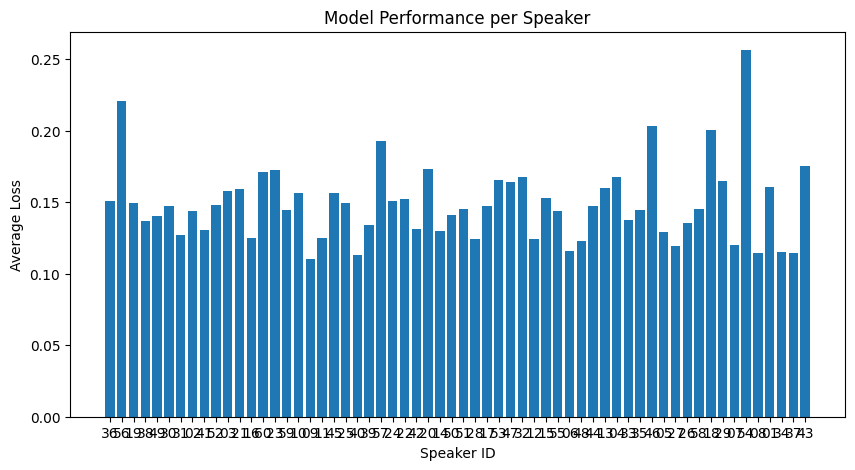

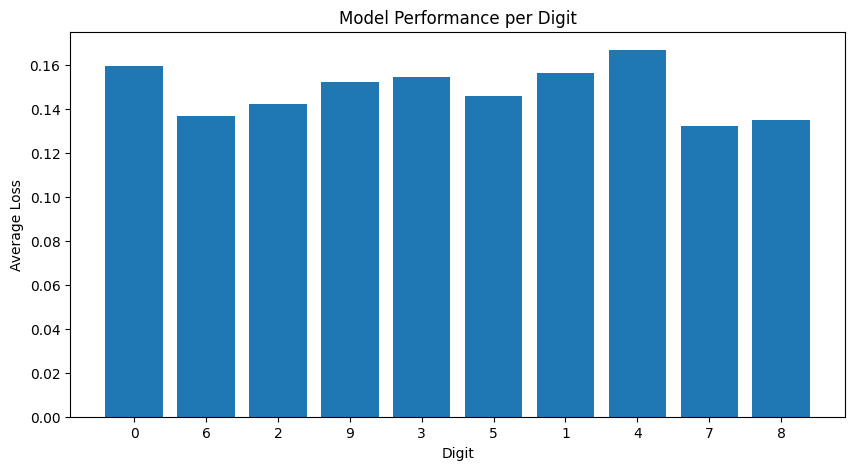

In [44]:
# Visualize speaker performance
speakers = list(per_speaker_loss.keys())
losses = list(per_speaker_loss.values())
plt.figure(figsize=(10, 5))
plt.bar(speakers, losses)
plt.xlabel('Speaker ID')
plt.ylabel('Average Loss')
plt.title('Model Performance per Speaker')
plt.show()

# Visualize digit performance
digits = list(per_digit_loss.keys())
losses = list(per_digit_loss.values())
plt.figure(figsize=(10, 5))
plt.bar(digits, losses)
plt.xlabel('Digit')
plt.ylabel('Average Loss')
plt.title('Model Performance per Digit')
plt.show()


## Results Summary

Test-set results of the full run (3,000 pairs). SNR is measured on z-normalised log-mel spectrograms:

| Model | Epochs | Test MSE | Noisy SNR | Denoised SNR | Improvement |
|---|---:|---:|---:|---:|---:|
| Convolutional autoencoder | 10 | 0.7347 | 1.80 dB | 2.50 dB | +0.70 dB |
| **U-Net (ResNet-34 encoder)** | 5 | **0.1485** | 1.80 dB | **9.49 dB** | **+7.70 dB** |

**Observations**

- The U-Net reduces the test MSE about five-fold and gains 7 dB more than the autoencoder, even with half
  as many epochs. Skip connections keep the time-frequency detail, and its output range is unrestricted.
- The autoencoder's loss flattens early at about 0.73 and barely improves after epoch 5.
- U-Net test MSE varies by speaker (about 0.11 to 0.26) and by digit (0.132 for "7" to 0.167 for "4").

**Known limitations of this setup**

- Recordings are split at random, so the same speakers appear in the training and test sets. These results
  do not measure performance on unseen speakers.
- Griffin-Lim reconstruction estimates the phase, so reconstructed audio contains artefacts, even for the
  clean spectrograms.
- Every recording is time-stretched to a fixed length and its spectrogram is resized to 128 × 128, which
  changes its timing.